<div dir="rtl">

# نوت‌بوک ۸: خط مبنا و معیارهای ارزیابی

**فاز ۱، تسک ۱۲**

سند می‌گوید: «یک خط مبنای بسیار ساده و قابل فهم تعریف کنید تا در فازهای بعدی بتوانید نشان دهید روش‌های پیچیده‌تر واقعاً ارزش افزوده دارند.»

این نوت‌بوک سه کار می‌کند:

۱. **شکل دقیق متغیر هدف** را تعیین می‌کند.
۲. **معیارهای عددی** هر لایه‌ی ارزیابی (بند ۹ کارت پروژه) را انتخاب می‌کند و دلیل هر انتخاب را می‌گوید.
۳. چند **خط مبنای ساده** را روی داده‌ی **آموزش** می‌سازد و روی داده‌ی **اعتبارسنجی** می‌سنجد.

**داده‌ی آزمون در این نوت‌بوک اصلاً بارگذاری نمی‌شود** (تصمیم تسک ۱۱).

</div>

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import average_precision_score, f1_score, mean_absolute_error

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from splits import assign_split
from text_utils import clean_text, word_count

cfg = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))
PROC = ROOT / cfg["data"]["processed_dir"]
FIG = ROOT / "figures"
REP = ROOT / "reports" / "phase1"
SEED = cfg["seed"]

pd.set_option("display.width", 200)
BAR, NEG, GREY = "#3B6EA8", "#B5523B", "#9a9a9a"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9,
})

import json
reviews = pd.read_parquet(PROC / "reviews_rc.parquet").drop_duplicates().reset_index(drop=True)
meta = pd.read_parquet(PROC / "meta_rc.parquet")
meta["subgroup"] = meta["categories"].map(lambda c: (json.loads(c) + [None] * 3)[2] or "(none)")
reviews["date"] = pd.to_datetime(reviews["timestamp"], unit="ms")
reviews["split"] = assign_split(reviews["date"], cfg)

# the test period is never loaded into this notebook
reviews = reviews[reviews["split"].isin(["train", "validation"])].reset_index(drop=True)
reviews = reviews.merge(meta[["parent_asin", "subgroup"]], on="parent_asin", how="left")
reviews["clean"] = reviews["text"].map(clean_text)
reviews["words"] = reviews["clean"].map(word_count)

train = reviews[reviews["split"] == "train"].reset_index(drop=True)
val = reviews[reviews["split"] == "validation"].reset_index(drop=True)
print(f"train: {len(train):,} reviews   validation: {len(val):,} reviews   (test not loaded)")

train: 478,426 reviews   validation: 142,597 reviews   (test not loaded)


<div dir="rtl">

## ۱. شکل متغیر هدف

امتیاز ۱ تا ۵ ستاره است. سه راه برای مدل کردنش داریم:

| شکل | مزیت | عیب |
|---|---|---|
| **عدد پیوسته** (۱ تا ۵) | ترتیب را حفظ می‌کند: اشتباه ۵ به‌جای ۴ کوچک‌تر از ۵ به‌جای ۱ است؛ «تغییر امتیاز» در لایه‌ی ۳ هم عدد است | فرض می‌کند فاصله‌ی ۱ تا ۲ با ۴ تا ۵ برابر است |
| **پنج دسته‌ی جدا** | فرضی درباره‌ی فاصله‌ها ندارد | ترتیب را نادیده می‌گیرد |
| **دودویی** (منفی ۱-۲ در برابر بقیه) | مستقیم به «شکایت» مربوط است | اطلاعات بین ۳، ۴ و ۵ را دور می‌ریزد |

**تصمیم:** متغیر هدف اصلی **امتیاز به‌صورت عدد** است، چون لایه‌ی ۳ ارزیابی «چند ستاره تغییر» را می‌سنجد و این فقط با هدف عددی معنا دارد. **تشخیص نقد منفی** (۱ و ۲ ستاره) به‌عنوان معیار مکمل گزارش می‌شود، چون شکایت‌ها هسته‌ی گزارش ما هستند.

</div>

<div dir="rtl">

## ۲. معیارها و دلیل انتخابشان

### چرا «دقت» (accuracy) نه؟

۶۴٪ امتیازها ۵ ستاره‌اند. مدلی که همیشه «۵» بگوید ۶۴٪ دقت دارد بدون اینکه یک کلمه بخواند. دقت عدم‌توازن را پنهان می‌کند.

### معیار اصلی لایه‌ی ۲: میانگین خطای مطلق متوازن (macro-MAE)

- **خطای مطلق** هر نقد: فاصله‌ی امتیاز پیش‌بینی‌شده تا امتیاز واقعی، به ستاره. مثلاً پیش‌بینی ۴ برای نقد ۲ ستاره یعنی خطای ۲.
- **MAE معمولی:** میانگین این خطاها روی همه‌ی نقدها. قابل فهم است («به‌طور متوسط چند ستاره اشتباه می‌کند») ولی چون بیشتر نقدها ۵ ستاره‌اند، مدلی که نقدهای منفی را خراب پیش‌بینی کند هم MAE خوبی می‌گیرد.
- **macro-MAE:** اول MAE را **جداگانه برای هر امتیاز واقعی** (۱، ۲، ۳، ۴، ۵) حساب می‌کنیم، بعد میانگین این پنج عدد را می‌گیریم. به هر امتیاز **وزن برابر** می‌دهد. پس مدلی که نقدهای ۱ ستاره را نفهمد، جریمه‌ی واقعی می‌شود.

**مزیت دوم macro-MAE:** چون هر امتیاز جدا سنجیده می‌شود، به **سهم** نقدهای منفی در داده وابسته نیست. در تسک ۱۱ دیدیم این سهم از آموزش (۱۶٫۵٪) تا آزمون (۲۲٫۶٪) عوض می‌شود؛ macro-MAE مقایسه‌ی بین سال‌ها را منصفانه‌تر می‌کند.

### معیارهای مکمل لایه‌ی ۲

| معیار | چه می‌سنجد |
|---|---|
| MAE معمولی | برای مقایسه با کارهای دیگر و قابل فهم بودن |
| **F1 نقد منفی** | وقتی نقد را منفی می‌نامیم (پیش‌بینی کمتر از ۲٫۵)، تعادل بین «چند تا از منفی‌ها را پیدا کردیم» و «چند تا از پیداشده‌ها واقعاً منفی بودند» |
| **میانگین دقت (AP) نقد منفی** | بدون نیاز به آستانه: مدل چقدر نقدهای منفی را بالای فهرست می‌گذارد. برای مدل تنبل برابر سهم نقدهای منفی است (حدود ۰٫۲) |

</div>

In [4]:
def macro_mae(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean([np.abs(y_pred[y_true == s] - s).mean() for s in range(1, 6)])

def evaluate(name, y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 1, 5)
    is_neg = y_true <= 2
    return {
        "baseline": name,
        "macro_MAE": macro_mae(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "F1_negative": f1_score(is_neg, y_pred < 2.5, zero_division=0),
        "AP_negative": average_precision_score(is_neg, -y_pred),
        **{f"MAE_{s}star": np.abs(y_pred[y_true == s] - s).mean() for s in range(1, 6)},
    }

<div dir="rtl">

## ۳. خط‌های مبنا

همه فقط از داده‌ی **آموزش** یاد می‌گیرند و روی **اعتبارسنجی** سنجیده می‌شوند. از ساده به پیچیده:

| # | خط مبنا | چه می‌کند |
|---|---|---|
| B0 | همیشه ۵ | پرتکرارترین امتیاز آموزش |
| B1 | میانگین کل | میانگین امتیاز آموزش برای همه |
| B2 | میانگین زیرگروه | میانگین امتیاز آموزش در زیرگروه همان محصول |
| B3 | سابقه‌ی محصول | میانگین امتیاز نقدهای **قبلی** همان محصول در آموزش؛ برای محصول جدید، میانگین زیرگروه |
| B4 | فقط طول متن | رگرسیون خطی روی لگاریتم تعداد کلمه؛ برای سنجیدن «میان‌بُر طول» که در نوت‌بوک ۵ دیدیم |
| B5 | متن ساده | کلمه‌ها و جفت‌کلمه‌ها با وزن TF-IDF و رگرسیون خطی (Ridge)؛ ساده‌ترین مدل متنی استاندارد |

**B5 مهم‌ترین خط مبناست:** روش فاز ۲ و ۳ (جنبه + جهت نظر + اطلاعات محصول + زمان) باید از آن بهتر باشد، وگرنه پیچیدگی‌اش توجیهی ندارد. در B5، واژه‌نامه و وزن‌های TF-IDF **فقط روی آموزش** ساخته می‌شوند (خطر نشت شماره‌ی ۶).

</div>

In [5]:
y_tr, y_va = train["rating"].to_numpy(), val["rating"].to_numpy()
results = []

# B0 / B1
results.append(evaluate("B0 always 5", y_va, np.full(len(val), train["rating"].mode()[0])))
results.append(evaluate("B1 global mean", y_va, np.full(len(val), y_tr.mean())))

# B2 sub-group mean (learnt on train)
sub_mean = train.groupby("subgroup")["rating"].mean()
results.append(evaluate("B2 sub-group mean", y_va, val["subgroup"].map(sub_mean).fillna(y_tr.mean())))

# B3 product history (train reviews of the product are all earlier than validation)
prod_mean = train.groupby("parent_asin")["rating"].agg(["mean", "size"])
prod_mean = prod_mean[prod_mean["size"] >= 5]["mean"]
b3 = val["parent_asin"].map(prod_mean)
b3 = b3.fillna(val["subgroup"].map(sub_mean)).fillna(y_tr.mean())
results.append(evaluate("B3 product history", y_va, b3))
print(f"validation reviews whose product has >= 5 train reviews: {val['parent_asin'].isin(prod_mean.index).mean():.1%}")

validation reviews whose product has >= 5 train reviews: 66.5%


In [6]:
# B4 length only
X_len_tr = np.log1p(train[["words"]].to_numpy())
X_len_va = np.log1p(val[["words"]].to_numpy())
b4 = Ridge(alpha=1.0).fit(X_len_tr, y_tr)
results.append(evaluate("B4 length only", y_va, b4.predict(X_len_va)))

# B5 TF-IDF + Ridge (vocabulary fitted on train only)
tfidf = TfidfVectorizer(min_df=5, max_features=200_000, ngram_range=(1, 2),
                        sublinear_tf=True, lowercase=True)
X_tr = tfidf.fit_transform(train["clean"])
X_va = tfidf.transform(val["clean"])
b5 = Ridge(alpha=1.0, random_state=SEED).fit(X_tr, y_tr)
b5_pred = b5.predict(X_va)
results.append(evaluate("B5 TF-IDF + Ridge", y_va, b5_pred))
print(f"TF-IDF vocabulary: {X_tr.shape[1]:,} terms (fitted on train only)")

TF-IDF vocabulary: 200,000 terms (fitted on train only)


In [7]:
res = pd.DataFrame(results).set_index("baseline").round(3)
res.to_csv(REP / "baselines_validation.csv")
res[["macro_MAE", "MAE", "F1_negative", "AP_negative"]]

,macro_MAE,MAE,F1_negative,AP_negative
baseline,,,,
B0 always 5,2.000,0.994,0.000,0.205
B1 global mean,1.487,1.220,0.000,0.205
B2 sub-group mean,1.478,1.223,0.000,0.207
B3 product history,1.493,1.141,0.022,0.302
B4 length only,1.451,1.203,0.000,0.228
B5 TF-IDF + Ridge,0.724,0.546,0.739,0.866


<div dir="rtl">

### خطا به تفکیک امتیاز واقعی

این جدول نشان می‌دهد چرا macro-MAE لازم است: مدل‌های ثابت روی ۵ ستاره‌ها خطای کمی دارند ولی روی ۱ ستاره‌ها خطای خیلی بزرگ.

</div>

In [8]:
res[[f"MAE_{s}star" for s in range(1, 6)]]

,MAE_1star,MAE_2star,MAE_3star,MAE_4star,MAE_5star
baseline,,,,,
B0 always 5,4.000,3.000,2.000,1.000,0.000
B1 global mean,3.145,2.145,1.145,0.145,0.855
B2 sub-group mean,3.126,2.135,1.136,0.123,0.869
B3 product history,3.073,2.128,1.179,0.377,0.708
B4 length only,3.101,2.054,1.067,0.187,0.847
B5 TF-IDF + Ridge,1.068,0.837,0.718,0.633,0.363


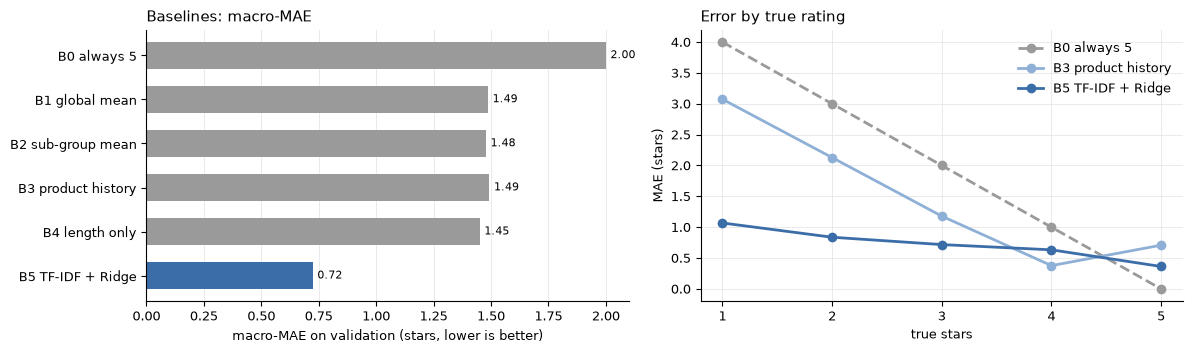

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
order = res.index.tolist()
colors = [GREY, GREY, GREY, GREY, GREY, BAR]

ax = axes[0]
ax.barh(order[::-1], res["macro_MAE"][::-1], color=colors[::-1], height=0.6)
for i, v in enumerate(res["macro_MAE"][::-1]):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("macro-MAE on validation (stars, lower is better)")
ax.set_title("Baselines: macro-MAE", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
stars = np.arange(1, 6)
for name, style in [("B0 always 5", dict(color=GREY, ls="--")),
                    ("B3 product history", dict(color="#8FB0D6")),
                    ("B5 TF-IDF + Ridge", dict(color=BAR))]:
    ax.plot(stars, res.loc[name, [f"MAE_{s}star" for s in stars]], marker="o", lw=2, label=name, **style)
ax.set_xticks(stars)
ax.set_xlabel("true stars")
ax.set_ylabel("MAE (stars)")
ax.set_title("Error by true rating", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "fig16_baselines.png", dpi=200, bbox_inches="tight")
plt.show()

<div dir="rtl">

### خطای B5 برای محصولات جدید در برابر دیده‌شده

طبق روش ارزیابی، عملکرد روی «محصولات جدید» (بدون نقد در آموزش) جدا گزارش می‌شود:

</div>

In [10]:
seen = val["parent_asin"].isin(set(train["parent_asin"]))
by_group = pd.DataFrame([
    evaluate("seen products", y_va[seen], b5_pred[seen]),
    evaluate("new products", y_va[~seen], b5_pred[~seen]),
]).set_index("baseline")[["macro_MAE", "MAE", "F1_negative", "AP_negative"]].round(3)
by_group["reviews"] = [seen.sum(), (~seen).sum()]
by_group

,macro_MAE,MAE,F1_negative,AP_negative,reviews
baseline,,,,,
seen products,0.719,0.542,0.747,0.867,110336
new products,0.740,0.559,0.710,0.863,32261


<div dir="rtl">

### کلمه‌هایی که B5 بیشترین وزن را به آن‌ها داده

برای اینکه خط مبنا «قابل فهم» باشد، وزن‌های مدل خطی را نگاه می‌کنیم. وزن منفی یعنی این کلمه امتیاز پیش‌بینی را پایین می‌آورد.

</div>

In [11]:
terms = np.array(tfidf.get_feature_names_out())
coef = b5.coef_
top = pd.DataFrame({
    "lowers rating": terms[np.argsort(coef)[:15]],
    "weight (-)": np.sort(coef)[:15].round(2),
    "raises rating": terms[np.argsort(coef)[::-1][:15]],
    "weight (+)": np.sort(coef)[::-1][:15].round(2),
})
top

,lowers rating,weight (-),raises rating,weight (+)
0,not,-5.89,not disappointed,4.55
1,worst,-4.40,be disappointed,4.04
2,broke,-4.09,not bad,3.84
3,useless,-4.01,not too,3.83
4,disappointed,-4.00,go wrong,3.74
5,disappointment,-3.94,not break,3.54
6,unusable,-3.85,contacted me,3.14
7,waste,-3.79,no problems,3.14
8,stopped,-3.78,not only,3.14
9,worse,-3.75,nothing broke,2.95


<div dir="rtl">

## ۴. معیارهای لایه‌های ۱، ۳ و ۴

این لایه‌ها در فازهای بعد اجرا می‌شوند، ولی **معیارهایشان الان ثبت می‌شود** تا بعد از دیدن نتایج انتخاب نشوند.

| لایه | معیار اصلی | معیار مکمل | خط مبنا |
|---|---|---|---|
| ۱. جنبه و جهت نظر | **F1** هر جنبه و میانگین متوازن آن‌ها (macro-F1) در برابر برچسب دستی | دقت تشخیص جهت نظر (مثبت/منفی) برای جنبه‌های درست‌تشخیص‌داده‌شده | جست‌وجوی کلمه‌های کلیدی هر جنبه |
| ۳. درستی پیشنهادها | **همبستگی رتبه‌ای اسپیرمن** بین تغییر پیش‌بینی‌شده و تغییر واقعی امتیاز (نسبت به هم‌زیرگروه‌ها) روی جفت بازه‌های متوالی | نرخ هم‌جهتی: در چند درصد جفت‌ها جهت تغییر (بالا یا پایین) درست پیش‌بینی شده | روش «پرتکرارترین شکایت»: وزن هر جنبه متناسب با سهم شکایت از آن |
| ۴. پایداری | همبستگی رتبه‌ای اولویت‌ها بین بازه‌های متوالی یک محصول | همپوشانی سه اولویت اول بین طول بازه‌های ۱، ۳ و ۶ ماهه | — |

**چرا همبستگی رتبه‌ای برای لایه‌ی ۳؟** برای صاحب محصول «ترتیب» اولویت‌ها مهم‌تر از عدد دقیق است. اسپیرمن می‌سنجد آیا جفت‌هایی که پیش‌بینی کردیم بیشتر بهتر می‌شوند، واقعاً بیشتر بهتر شده‌اند یا نه، بدون اینکه به مقیاس دقیق حساس باشد.

</div>

<div dir="rtl">

## ۵. جمع‌بندی

### چه دیدیم

| خط مبنا | macro-MAE | MAE | F1 منفی | AP منفی |
|---|---|---|---|---|
| B0 همیشه ۵ | ۲٫۰۰ | ۰٫۹۹ | ۰ | ۰٫۲۰ |
| B1 میانگین کل | ۱٫۴۹ | ۱٫۲۲ | ۰ | ۰٫۲۰ |
| B2 میانگین زیرگروه | ۱٫۴۸ | ۱٫۲۲ | ۰ | ۰٫۲۱ |
| B3 سابقه‌ی محصول | ۱٫۴۹ | ۱٫۱۴ | ۰٫۰۲ | ۰٫۳۰ |
| B4 فقط طول متن | ۱٫۴۵ | ۱٫۲۰ | ۰ | ۰٫۲۳ |
| **B5 متن ساده (TF-IDF + Ridge)** | **۰٫۷۲** | **۰٫۵۵** | **۰٫۷۴** | **۰٫۸۷** |

۱. **MAE معمولی گول‌زننده است.** B0 بین روش‌های بدون متن کمترین MAE را دارد (۰٫۹۹)، ولی بدترین macro-MAE را (۲٫۰۰)، چون روی نقدهای ۱ ستاره ۴ ستاره خطا دارد. انتخاب macro-MAE به‌عنوان معیار اصلی همین‌جا توجیه می‌شود.
۲. **بدون خواندن متن کاری از پیش نمی‌رود.** زیرگروه، سابقه‌ی محصول و طول نقد (B2 تا B4) تقریباً هیچ بهبودی نسبت به میانگین کل نمی‌دهند (همه حدود ۱٫۵ ستاره).
۳. **ساده‌ترین مدل متنی خطا را نصف می‌کند** (از حدود ۱٫۵ به ۰٫۷۲ ستاره) و AP نقد منفی را از ۰٫۲ (سطح شانس) به ۰٫۸۷ می‌رساند.
۴. **B5 حفظ نکرده، تعمیم داده.** روی محصولات جدید macro-MAE برابر ۰٫۷۴ است و روی محصولات دیده‌شده ۰٫۷۲. این مهم است چون ۵۹٪ نقدهای آزمون مال محصولات جدیدند.
۵. **B5 با منفی‌سازی مشکل دارد.** «not» منفی‌ترین وزن را گرفته و «not disappointed» مثبت‌ترین. بیشترین خطای B5 هم روی نقدهای ۱ ستاره است (۱٫۰۷)، چون پیش‌بینی‌ها را به سمت وسط می‌کشد.

### چرا مهم است

لایه‌ی ۲ ارزیابی حالا یک **حد مشخص** دارد. اگر مدل فاز ۳ (جنبه، جهت نظر، اطلاعات محصول و زمان) از B5 بهتر نباشد، پیچیدگی‌اش توجیهی ندارد. یافته‌ی ۵ هم نشان می‌دهد شمردن کلمه‌ها برای تشخیص شکایت از هر جنبه کافی نیست.

### تصمیم‌ها (ثبت در کارت پروژه، بندهای ۷، ۸ و ۹)

- **متغیر هدف:** امتیاز ۱ تا ۵ به‌صورت عدد. تشخیص نقد منفی (۱ و ۲ ستاره) معیار مکمل است.
- **معیار اصلی لایه‌ی ۲:** macro-MAE. معیارهای مکمل: MAE، F1 نقد منفی (آستانه‌ی ۲٫۵) و AP نقد منفی.
- **خط مبنای اصلی:** B5. **حدی که فاز ۳ باید از آن بهتر شود: macro-MAE کمتر از ۰٫۷۲۴ روی اعتبارسنجی.** B0 و B3 هم به‌عنوان مرجع بدون متن گزارش می‌شوند.
- **فاز ۲:** روش جهت نظر باید منفی‌سازی را بفهمد؛ این یکی از موارد بررسی در برچسب‌گذاری دستی لایه‌ی ۱ است.
- داده‌ی آزمون در این نوت‌بوک بارگذاری نشد و تا پایان فاز ۳ قفل می‌ماند.

### محدودیت‌ها

- تنظیمات B5 (alpha=1، min_df=5، حداکثر ۲۰۰ هزار عبارت) عمداً تنظیم نشده‌اند. در فاز ۳ نسخه‌ی تنظیم‌شده‌ی B5 (فقط با اعتبارسنجی) هم گزارش می‌شود تا مقایسه منصفانه باشد.
- آستانه‌ی ۲٫۵ برای F1 قراردادی است؛ AP به همین دلیل کنارش آمده.
- B5 روی نسخه‌های مختلف کتابخانه ممکن است در رقم سوم اعشار کمی فرق کند.

</div>